# Análisis y pronóstico de ventas — JR Parking
**Tópico:** Inteligencia Artificial Aplicada a los Negocios · Unidad 2
**Docente:** Dr. José Antonio Sánchez Valdés

**Equipo:**
* Valeria Nohemi Yañez Villarreal — 22481232
* Yesenia Aguirre Moncada — 22481216
* Fernando Salvador Rocha de la Garza — 22480295
* Alexa Paola Rodriguez Sandoval — 22480306
* Gerardo Osmar Esquivel Palacios — 21480798
* Raul Alexis Carrizales Dana — 23481198

> ⚠️ **Datos simulados con fines académicos**: es la misma base de 36 meses presentada en el Proyecto de la Unidad 1. Se tomó como base 998,400 piezas anuales en 2023 y se aplicó crecimiento moderado y estacionalidad del mercado agrícola. No contiene datos personales de clientes.

### Cómo ejecutar
* **Google Colab:** *Archivo → Subir notebook* → *Entorno de ejecución → Ejecutar todas*. Cuando lo pida, subir `datos/ventas_jrparking_original.csv`.
* **Local:** abrir este notebook desde la carpeta `codigo/` y ejecutar *Run All*.

El notebook guarda la base depurada en `datos/` y los resultados que usa el dashboard en `datos/resultados/`.

## 1. Problema de negocio
**JR Parking** (Juárez, Nuevo León) fabrica **cajas de plástico por reciclaje e inyección** para el sector agrícola: la **Caja Limonera** y la **Caja Nailea**. Vende por **venta directa** y **venta en línea**.

**Situación:** la demanda es muy estacional. Sube en la primera mitad del año, llega a su punto más alto en mayo–julio (cosecha) y cae en noviembre–diciembre. Si la producción no se anticipa, faltan cajas en temporada alta y sobra inventario en temporada baja.

**Decisión que apoya el pronóstico:** cuántas cajas producir y cuánta materia prima (plástico reciclado) comprar para **enero, febrero y marzo de 2026**, el arranque de la temporada alta.

**Pregunta de negocio (Unidad 1):** *¿Cómo puede JR Parking predecir con mayor precisión la demanda mensual de cajas de plástico para optimizar su producción e inventario, evitando faltantes en temporada alta y excedentes en temporada baja?*

**Preguntas específicas**
1. ¿Cómo evolucionaron las ventas de 2023 a 2025 y qué tan fuerte es la estacionalidad?
2. ¿Qué producto y qué canal concentran las ventas?
3. ¿Cuántas cajas se venderán en total en enero–marzo de 2026 y qué tan confiable es ese pronóstico?

In [1]:
# Librerías necesarias (todas vienen preinstaladas en Google Colab)
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})
miles = mtick.FuncFormatter(lambda x, _: f"{x/1e3:,.0f} mil")
pesos = mtick.FuncFormatter(lambda x, _: f"${x/1e6:,.2f} M")
MESES = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
AZUL, NARANJA, VERDE = "#1f5f8b", "#e67e22", "#2e8b57"

In [2]:
# Rutas del proyecto: funciona si el notebook está en codigo/ (local) o en Colab
RAIZ = Path.cwd().parent if Path.cwd().name == "codigo" else Path.cwd()
ARCHIVO = RAIZ / "datos" / "ventas_jrparking_original.csv"

if not ARCHIVO.exists():                       # Colab: pedir el archivo si no está
    try:
        from google.colab import files
        print("Sube el archivo ventas_jrparking_original.csv")
        subido = files.upload()
        ARCHIVO.parent.mkdir(parents=True, exist_ok=True)
        ARCHIVO.write_bytes(subido[list(subido)[0]])
    except ImportError:
        raise FileNotFoundError(f"No se encontró {ARCHIVO}")

SALIDA = RAIZ / "datos" / "resultados"
SALIDA.mkdir(parents=True, exist_ok=True)
print("Archivo de datos:", ARCHIVO)

Archivo de datos: /home/claude/Unidad2_GRUPO_JRParking/datos/ventas_jrparking_original.csv


## 2. Preparación de los datos
### 2.1 Carga y revisión inicial
La base viene de la hoja de Excel de la Unidad 1. **Cada fila representa las ventas de un mes**, con el producto, canal, cantidad (piezas), precio unitario, subtotal, IVA (16 %) y venta total, en **pesos mexicanos (MXN)**. Periodo: **enero 2023 a diciembre 2025 (36 meses)**.

Se lee todo como texto para revisar los formatos antes de convertir.

In [3]:
crudo = pd.read_csv(ARCHIVO, dtype=str)
print("Filas:", len(crudo), "| Columnas:", crudo.shape[1])
crudo.info()
crudo.head()

Filas: 36 | Columnas: 12
<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Fecha              36 non-null     str  
 1   Mes                36 non-null     str  
 2   Producto/servicio  36 non-null     str  
 3   Categoría          36 non-null     str  
 4   Cantidad           36 non-null     str  
 5   Precio unitario    36 non-null     str  
 6   Subtotal           36 non-null     str  
 7   IVA                36 non-null     str  
 8   Venta total        36 non-null     str  
 9   Cliente/segmento   36 non-null     str  
 10  Zona/sucursal      36 non-null     str  
 11  Vendedor/canal     36 non-null     str  
dtypes: str(12)
memory usage: 8.5 KB


,Fecha,Mes,Producto/servicio,Categoría,Cantidad,Precio unitario,Subtotal,IVA,Venta total,Cliente/segmento,Zona/sucursal,Vendedor/canal
0,01/01/2023,Enero,Caja Limonera,Inyección de plástico,"72,883",$14.00,"$1,020,362.00","$163,257.92","$1,183,619.92",Agrícola,"Juárez, Nuevo León",Venta directa
1,01/02/2023,Febrero,Caja Nailea,Inyección de plástico,"74,880",$14.00,"$1,048,320.00","$167,731.20","$1,216,051.20",Agrícola,"Juárez, Nuevo León",Venta directa
2,01/03/2023,Marzo,Caja Limonera,Inyección de plástico,"81,869",$14.00,"$1,146,166.00","$183,386.56","$1,329,552.56",Agrícola,"Juárez, Nuevo León",Venta en línea
3,01/04/2023,Abril,Caja Limonera,Inyección de plástico,"89,856",$14.00,"$1,257,984.00","$201,277.44","$1,459,261.44",Agrícola,"Juárez, Nuevo León",Venta directa
4,01/05/2023,Mayo,Caja Nailea,Inyección de plástico,"99,840",$14.00,"$1,397,760.00","$223,641.60","$1,621,401.60",Agrícola,"Juárez, Nuevo León",Venta directa


**Problemas de formato detectados:**
* Las cantidades y los importes son **texto** con separador de miles y signo de pesos (`"$1,020,362.00"`), así que no se pueden sumar.
* La fecha está en formato **dd/mm/aaaa** (`01/02/2023` = 1 de febrero). Si se lee con el formato de EE. UU. (mm/dd), se confundiría con el 2 de enero.
* Los nombres de columna tienen espacios, acentos y "/", lo que complica el código.

In [4]:
df = crudo.copy()

# 1) Renombrar columnas a nombres simples
df.columns = ["fecha", "mes_texto", "producto", "categoria", "cantidad", "precio_unitario",
              "subtotal", "iva", "venta_total", "segmento", "zona", "canal"]

# 2) Fecha en formato día/mes/año
df["fecha"] = pd.to_datetime(df["fecha"], format="%d/%m/%Y")

# 3) Quitar "$" y "," y convertir a número
def a_numero(col):
    return pd.to_numeric(col.str.replace(r"[$,\s]", "", regex=True))

for c in ["cantidad", "precio_unitario", "subtotal", "iva", "venta_total"]:
    df[c] = a_numero(df[c])
df["cantidad"] = df["cantidad"].astype(int)

# 4) Limpiar espacios en textos
for c in ["mes_texto", "producto", "categoria", "segmento", "zona", "canal"]:
    df[c] = df[c].str.strip()

df.dtypes

fecha              datetime64[us]
mes_texto                     str
producto                      str
categoria                     str
cantidad                    int64
precio_unitario           float64
subtotal                  float64
iva                       float64
venta_total               float64
segmento                      str
zona                          str
canal                         str
dtype: object

### 2.2 Revisión de calidad

In [5]:
NOMBRES_MES = ["Enero","Febrero","Marzo","Abril","Mayo","Junio","Julio","Agosto",
               "Septiembre","Octubre","Noviembre","Diciembre"]
meses_esperados = pd.date_range("2023-01-01", "2025-12-01", freq="MS")

revision = pd.Series({
    "Filas duplicadas": df.duplicated().sum(),
    "Meses repetidos": df["fecha"].duplicated().sum(),
    "Valores faltantes": df.isna().sum().sum(),
    "Meses faltantes en el periodo": len(meses_esperados.difference(df["fecha"])),
    "Cantidades <= 0 (devoluciones o errores)": (df["cantidad"] <= 0).sum(),
    "Precio unitario <= 0": (df["precio_unitario"] <= 0).sum(),
    "Mes en texto distinto a la fecha": (df["mes_texto"] != df["fecha"].dt.month.map(lambda m: NOMBRES_MES[m-1])).sum(),
    "Subtotal != cantidad x precio": ((df["subtotal"] - df["cantidad"] * df["precio_unitario"]).abs() > 0.01).sum(),
    "IVA != 16 % del subtotal": ((df["iva"] - df["subtotal"] * 0.16).abs() > 0.01).sum(),
    "Venta total != subtotal + IVA": ((df["venta_total"] - df["subtotal"] - df["iva"]).abs() > 0.01).sum(),
}, name="registros con problema")
print("Productos:", df["producto"].unique())
print("Canales:", df["canal"].unique())
print("Precio por año:", df.groupby(df["fecha"].dt.year)["precio_unitario"].unique().to_dict())
revision.to_frame()

Productos: <ArrowStringArray>
['Caja Limonera', 'Caja Nailea']
Length: 2, dtype: str
Canales: <ArrowStringArray>
['Venta directa', 'Venta en línea']
Length: 2, dtype: str
Precio por año: {2023: array([14.]), 2024: array([14.5]), 2025: array([15.])}


,registros con problema
Filas duplicadas,0
Meses repetidos,0
Valores faltantes,0
Meses faltantes en el periodo,0
Cantidades <= 0 (devoluciones o errores),0
Precio unitario <= 0,0
Mes en texto distinto a la fecha,0
Subtotal != cantidad x precio,0
IVA != 16 % del subtotal,0
Venta total != subtotal + IVA,0


### 2.3 Resultado de la limpieza y justificación
| Revisión | Resultado | Tratamiento |
|---|---|---|
| Tipos de datos | Cantidades e importes venían como texto con "$" y "," | Se convirtieron a número. |
| Fechas | Formato dd/mm/aaaa | Se convirtieron indicando el formato explícitamente, para no confundir día y mes. |
| Duplicados | 0 | No se eliminó nada. |
| Valores faltantes | 0 | No hubo que imputar. |
| Meses faltantes | 0 (36 meses consecutivos) | **No hay periodos sin ventas**, así que no se rellena nada. |
| Devoluciones / ventas negativas | 0 | La base es un **resumen mensual** de ventas y **no registra devoluciones**. Por eso las ventas analizadas son las ventas registradas. Es una limitación: si hubiera devoluciones, las ventas reales netas serían menores. |
| Consistencia aritmética | Subtotal, IVA y total cuadran en las 36 filas | Se valida la fórmula **Subtotal = Cantidad × Precio unitario**; IVA = 16 %. |
| Totales anuales | Coinciden con el diagnóstico de la Unidad 1 | Validación cruzada (siguiente celda). |

**Variable de ventas:** se usa el **Subtotal (ventas antes de IVA)**, porque el IVA no es ingreso del negocio, sino un impuesto que se traslada al SAT. Para el pronóstico se usa la **cantidad de piezas**, porque es lo que se debe producir.

**Observación de estructura:** cada mes tiene **un solo renglón** con un solo producto y un solo canal (Caja Limonera en 24 meses y Caja Nailea en 12; venta en línea en marzo, junio, septiembre y diciembre). Los totales "por producto" y "por canal" reflejan esa asignación mensual, no la mezcla real de ventas dentro de cada mes.

In [6]:
# Comprobaciones automáticas: si alguna falla, el notebook se detiene
assert revision.sum() == 0, "Hay problemas de calidad sin resolver"
assert len(df) == 36 and df["fecha"].is_monotonic_increasing

# Validación cruzada con el diagnóstico de la Unidad 1
anual = df.groupby(df["fecha"].dt.year).agg(piezas=("cantidad", "sum"), ventas_sin_iva=("subtotal", "sum"))
unidad1 = pd.DataFrame({"piezas": [998_400, 1_048_320, 1_111_219],
                        "ventas_sin_iva": [13_977_600, 15_200_640, 16_668_285]}, index=[2023, 2024, 2025])
assert (anual.round(2) == unidad1).all().all(), "Los totales no coinciden con la Unidad 1"
print("✔ Los totales anuales coinciden con el diagnóstico de la Unidad 1")

# Guardar base depurada
df["anio"] = df["fecha"].dt.year
df["mes"] = df["fecha"].dt.month
DEPURADA = RAIZ / "datos" / "ventas_jrparking_depurada.csv"
df.to_csv(DEPURADA, index=False, encoding="utf-8")
print("Base depurada guardada en", DEPURADA)

✔ Los totales anuales coinciden con el diagnóstico de la Unidad 1
Base depurada guardada en /home/claude/Unidad2_GRUPO_JRParking/datos/ventas_jrparking_depurada.csv


## 3. Análisis exploratorio

In [7]:
anual["crecimiento_piezas_%"] = anual["piezas"].pct_change() * 100
anual["crecimiento_ventas_%"] = anual["ventas_sin_iva"].pct_change() * 100
anual["precio_promedio"] = anual["ventas_sin_iva"] / anual["piezas"]
print(f"Total 36 meses: {df['cantidad'].sum():,} piezas · ${df['subtotal'].sum():,.2f} MXN sin IVA "
      f"(${df['venta_total'].sum():,.2f} con IVA)")
anual

Total 36 meses: 3,157,939 piezas · $45,846,525.00 MXN sin IVA ($53,181,969.00 con IVA)


,piezas,ventas_sin_iva,crecimiento_piezas_%,crecimiento_ventas_%,precio_promedio
fecha,,,,,
2023,998400,"13,977,600.00",NaN,NaN,14.00
2024,1048320,"15,200,640.00",5.00,8.75,14.50
2025,1111219,"16,668,285.00",6.00,9.66,15.00


**Interpretación:** las piezas crecieron **5.0 %** en 2024 y **6.0 %** en 2025. Las ventas en pesos crecieron más (**8.8 %** y **9.7 %**) porque además el precio subió de $14.00 a $14.50 y luego a $15.00. Es decir, **una parte del crecimiento en pesos se debe al precio y no a más cajas vendidas**.

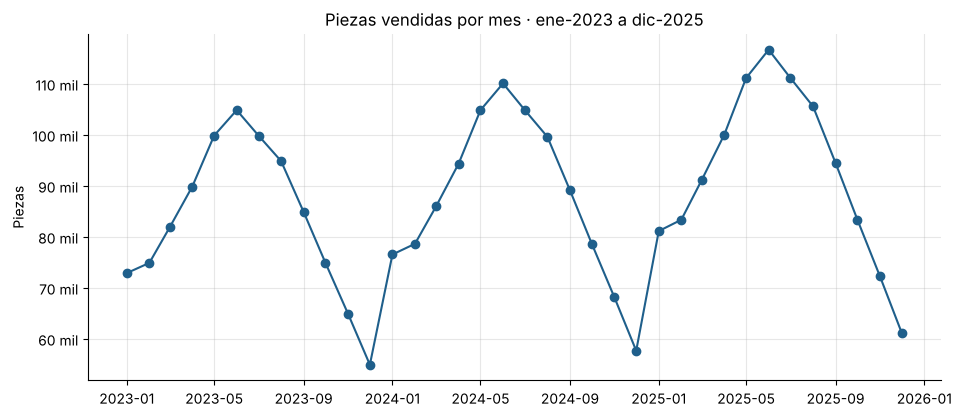

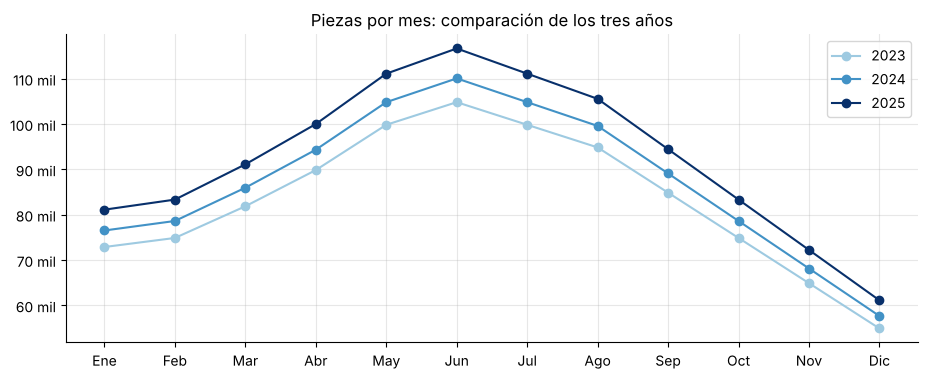

In [8]:
serie = df.set_index("fecha")["cantidad"].asfreq("MS")      # serie mensual de piezas
fig, ax = plt.subplots()
ax.plot(serie.index, serie, marker="o", color=AZUL)
ax.yaxis.set_major_formatter(miles)
ax.set_title("Piezas vendidas por mes · ene-2023 a dic-2025")
ax.set_ylabel("Piezas")
plt.show()

# Comparación año contra año
fig, ax = plt.subplots(figsize=(11, 4))
for anio, color in zip([2023, 2024, 2025], ["#9ecae1", "#4292c6", "#08306b"]):
    s = df[df.anio == anio]
    ax.plot(MESES, s["cantidad"], marker="o", label=str(anio), color=color)
ax.yaxis.set_major_formatter(miles); ax.legend(); ax.set_title("Piezas por mes: comparación de los tres años")
plt.show()

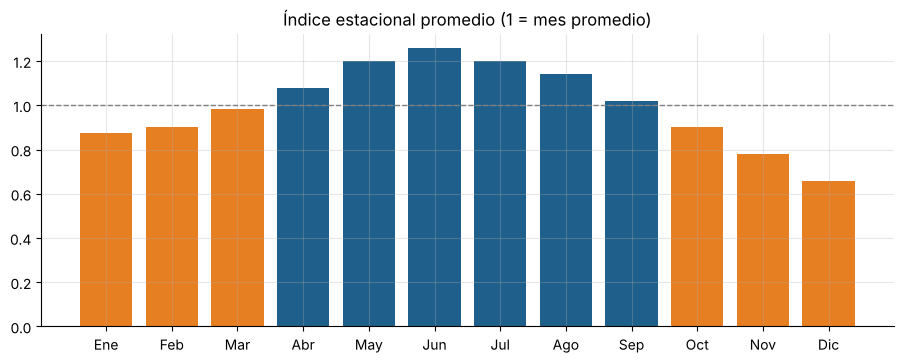

Junio está +26% y diciembre -34% respecto al mes promedio.
Junio vende 1.9 veces lo que vende diciembre.


,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
índice,0.88,0.90,0.98,1.08,1.20,1.26,1.20,1.14,1.02,0.90,0.78,0.66


In [9]:
# Índice estacional: piezas del mes / promedio mensual de su año
df["indice_estacional"] = df["cantidad"] / df.groupby("anio")["cantidad"].transform("mean")
estacional = df.groupby("mes")["indice_estacional"].mean()
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.bar(MESES, estacional.values, color=[NARANJA if v < 1 else AZUL for v in estacional.values])
ax.axhline(1, color="gray", ls="--", lw=1)
ax.set_title("Índice estacional promedio (1 = mes promedio)")
plt.show()
print(f"Junio está {estacional[6]-1:+.0%} y diciembre {estacional[12]-1:+.0%} respecto al mes promedio.")
print(f"Junio vende {estacional[6]/estacional[12]:.1f} veces lo que vende diciembre.")
estacional.set_axis(MESES).round(3).to_frame("índice").T

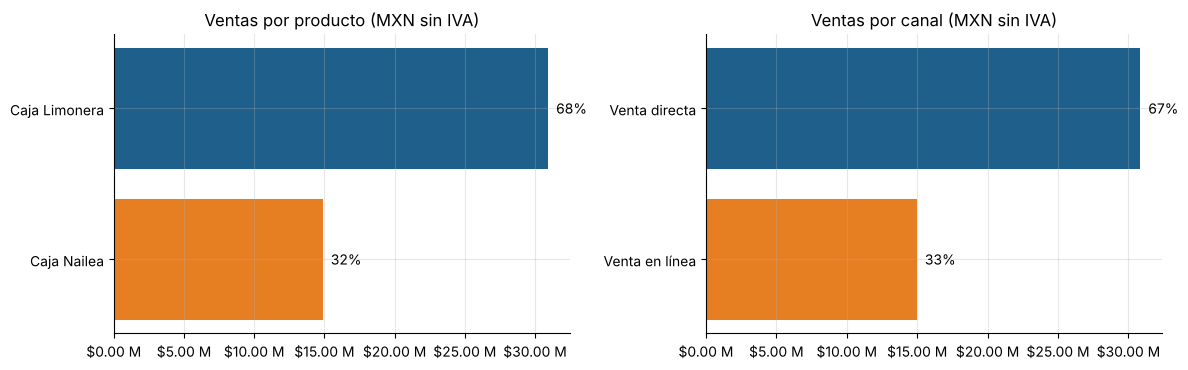

,meses,piezas,ventas_sin_iva
producto,,,
Caja Limonera,24,2131609,"30,946,407.00"
Caja Nailea,12,1026330,"14,900,118.00"


In [10]:
# Ventas por producto y por canal
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, titulo in [(axs[0], "producto", "Ventas por producto"), (axs[1], "canal", "Ventas por canal")]:
    t = df.groupby(col)["subtotal"].sum().sort_values()
    ax.barh(t.index, t.values, color=[NARANJA, AZUL][:len(t)])
    ax.xaxis.set_major_formatter(pesos); ax.set_title(titulo + " (MXN sin IVA)")
    for i, v in enumerate(t.values):
        ax.text(v, i, f"  {v/t.sum():.0%}", va="center")
plt.tight_layout(); plt.show()
df.groupby("producto").agg(meses=("fecha", "count"), piezas=("cantidad", "sum"), ventas_sin_iva=("subtotal", "sum"))

**Interpretación:**
* **Estacionalidad muy marcada:** las ventas suben de enero a junio, llegan a su máximo en **junio** (≈ 26 % arriba del mes promedio) y caen a su mínimo en **diciembre** (≈ 34 % abajo). Junio vende cerca de **1.9 veces** lo que diciembre. Es el ciclo de cosecha y empaque del sector agrícola.
* **El patrón se repite igual los tres años** y solo crece de nivel: las tres curvas son paralelas.
* **Caja Limonera** es el producto con más ventas (≈ 67.5 % de las piezas), lo mismo que se concluyó en la Unidad 1. Hay que considerar que en la base está asignada a 24 de los 36 meses.
* **Venta directa** concentra ≈ 67 % de las ventas. La venta en línea aparece solo en los meses de cierre de trimestre.

## 4. Pronóstico
**Objetivo:** pronosticar la **cantidad total de piezas** (ambos productos) de los tres meses siguientes al último dato: **enero, febrero y marzo de 2026**. El importe en pesos se estima después multiplicando por el precio.

**Método elegido — Holt-Winters (suavizamiento exponencial triple):** estima tres componentes: el **nivel** de ventas, la **tendencia** y un **factor estacional** para cada mes del año. Se eligió porque el análisis mostró justamente una tendencia creciente con estacionalidad anual repetitiva. Configuración:
* tendencia **aditiva**,
* estacionalidad **multiplicativa** (los picos crecen en proporción al negocio: junio siempre ≈ 1.25 veces el promedio),
* periodo estacional de **12 meses**.

Los parámetros de suavizamiento (α nivel, β tendencia, γ estacionalidad) se eligen con una **búsqueda en rejilla**: se prueban cientos de combinaciones y se elige la de menor error **dentro del entrenamiento**. Se usa rejilla en lugar del optimizador automático porque así el resultado es idéntico en cualquier versión de *statsmodels* (Colab o local).

Un α alto (cercano a 1) significa que el nivel sigue muy de cerca al último dato; β y γ cercanos a 0 significan que la tendencia y la estacionalidad son estables y se aprenden de toda la historia.

**Pronóstico básico de comparación — ingenuo:** repetir la última venta mensual observada.

## 5. Evaluación
Se reservan los **últimos 3 meses (oct, nov y dic 2025)** como prueba. Ambos métodos se entrenan **solo con ene-2023 a sep-2025 (33 meses)**, respetando el orden temporal: el modelo nunca "ve" los meses que va a predecir.

In [11]:
H = 3
entrena, prueba = serie.iloc[:-H], serie.iloc[-H:]
print(f"Entrenamiento: {entrena.index[0]:%b-%Y} a {entrena.index[-1]:%b-%Y} ({len(entrena)} meses)")
print(f"Prueba:        {prueba.index[0]:%b-%Y} a {prueba.index[-1]:%b-%Y} ({len(prueba)} meses)")
assert entrena.index.max() < prueba.index.min()      # no hay fuga de información futura

def modelo_hw(y, alfa, beta, gamma):
    # Holt-Winters: tendencia aditiva, estacionalidad multiplicativa de 12 meses
    return ExponentialSmoothing(y, trend="add", seasonal="mul", seasonal_periods=12,
                                initialization_method="heuristic").fit(
        smoothing_level=alfa, smoothing_trend=beta, smoothing_seasonal=gamma, optimized=False)

def ajustar_hw(y):
    # Búsqueda en rejilla: elige alfa, beta y gamma con el menor error cuadrático (sse)
    # DENTRO de los datos recibidos. Es determinista (mismo resultado en cualquier computadora).
    rejilla = np.round(np.arange(0, 0.55, 0.05), 2)
    alfas = np.round(np.arange(0.05, 1.0, 0.05), 2)
    mejor = min(((modelo_hw(y, a, b, g).sse, a, b, g)
                 for a in alfas for b in rejilla if b <= a for g in rejilla if g <= 1 - a),
                key=lambda x: x[0])
    return modelo_hw(y, *mejor[1:])

hw_prueba = ajustar_hw(entrena)
print("Parámetros elegidos con el entrenamiento: alfa={smoothing_level:.2f}, beta={smoothing_trend:.2f}, "
      "gamma={smoothing_seasonal:.2f}".format(**hw_prueba.params))

pred_hw = hw_prueba.forecast(H).round()
pred_ingenuo = pd.Series(entrena.iloc[-1], index=prueba.index)     # última venta observada (sep-2025)

evaluacion = pd.DataFrame({"real": prueba, "holt_winters": pred_hw, "ingenuo": pred_ingenuo})
evaluacion["error_abs_hw"] = (evaluacion["real"] - evaluacion["holt_winters"]).abs()
evaluacion["error_abs_ingenuo"] = (evaluacion["real"] - evaluacion["ingenuo"]).abs()

PRECIO_2025 = df.loc[df.anio == 2025, "precio_unitario"].iloc[0]    # $15.00 en todo 2025
mae = pd.DataFrame({
    "metodo": ["Holt-Winters", "Ingenuo (última venta)"],
    "MAE_piezas": [mean_absolute_error(prueba, pred_hw), mean_absolute_error(prueba, pred_ingenuo)],
})
mae["MAE_MXN"] = mae["MAE_piezas"] * PRECIO_2025        # en la prueba el precio fue $15 todos los meses
mae["MAE_%_venta_promedio"] = mae["MAE_piezas"] / prueba.mean() * 100
display(evaluacion)
mae

Entrenamiento: Jan-2023 a Sep-2025 (33 meses)
Prueba:        Oct-2025 a Dec-2025 (3 meses)


Parámetros elegidos con el entrenamiento: alfa=0.95, beta=0.05, gamma=0.00


,real,holt_winters,ingenuo,error_abs_hw,error_abs_ingenuo
2025-10-01,83341,"83,315.00",94454,26.00,11113
2025-11-01,72229,"72,152.00",94454,77.00,22225
2025-12-01,61117,"60,983.00",94454,134.00,33337


,metodo,MAE_piezas,MAE_MXN,MAE_%_venta_promedio
0,Holt-Winters,79.00,"1,185.00",0.11
1,Ingenuo (última venta),"22,225.00","333,375.00",30.77


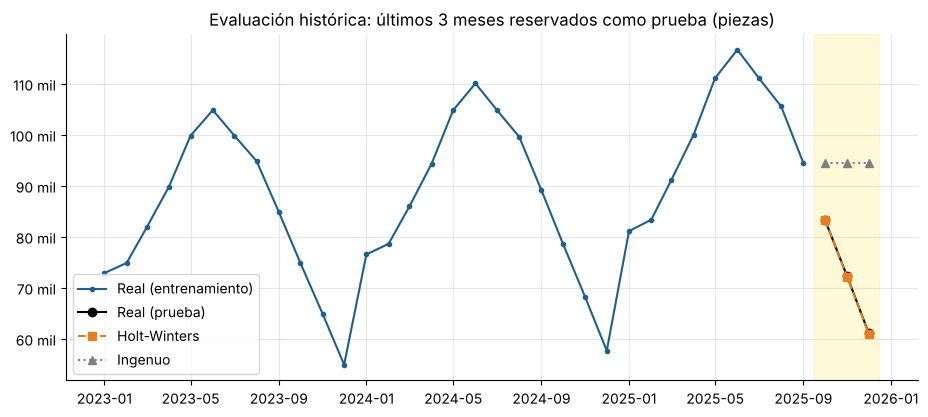

Holt-Winters reduce el error 99.6% frente al pronóstico ingenuo.


In [12]:
fig, ax = plt.subplots()
ax.plot(entrena.index, entrena, color=AZUL, marker="o", ms=3, label="Real (entrenamiento)")
ax.plot(prueba.index, prueba, color="black", marker="o", label="Real (prueba)")
ax.plot(pred_hw.index, pred_hw, color=NARANJA, marker="s", ls="--", label="Holt-Winters")
ax.plot(pred_ingenuo.index, pred_ingenuo, color="gray", marker="^", ls=":", label="Ingenuo")
ax.axvspan(prueba.index[0] - pd.Timedelta(days=15), prueba.index[-1] + pd.Timedelta(days=15), color="gold", alpha=.15)
ax.yaxis.set_major_formatter(miles); ax.legend()
ax.set_title("Evaluación histórica: últimos 3 meses reservados como prueba (piezas)")
plt.show()

mejora = 1 - mae["MAE_piezas"].iloc[0] / mae["MAE_piezas"].iloc[1]
print(f"Holt-Winters reduce el error {mejora:.1%} frente al pronóstico ingenuo.")

**Interpretación del MAE:**
* **Holt-Winters** se equivocó en promedio solo **79 piezas por mes** (≈ 0.1 % de la venta mensual). El **ingenuo** se equivocó más de **22 mil piezas por mes** (≈ 30 %), porque supuso que de octubre a diciembre se vendería lo mismo que en septiembre e ignoró la caída de fin de año.
* ⚠️ **Advertencia importante:** un error tan pequeño se explica porque los datos son **simulados con un patrón perfectamente regular**: cada año es exactamente el anterior × 1.05 o × 1.06. Con ventas reales (clima, pedidos grandes, competencia) el error sería bastante mayor. El resultado demuestra que el método captura bien la tendencia y la estacionalidad, pero **no debe interpretarse como la precisión esperada en la realidad**.

## 6. Proyección final (enero–marzo 2026)
Con el método seleccionado (Holt-Winters) **se vuelve a ajustar con los 36 meses** (repitiendo la búsqueda de parámetros) y se proyectan los tres meses futuros.

**Rango de planeación:** como el error del modelo en datos simulados es casi cero, un intervalo estadístico sería engañosamente estrecho. Para planear, se usa un **rango de ±5 %**, que equivale aproximadamente a la variación del crecimiento anual observado (5 %–6 %).

In [13]:
hw_final = ajustar_hw(serie)
print("Parámetros del modelo final: alfa={smoothing_level:.2f}, beta={smoothing_trend:.2f}, "
      "gamma={smoothing_seasonal:.2f}".format(**hw_final.params))
futuro = hw_final.forecast(H).round()
MARGEN = 0.05

pronostico = pd.DataFrame({
    "pronostico_piezas": futuro,
    "minimo_piezas_-5%": (futuro * (1 - MARGEN)).round(),
    "maximo_piezas_+5%": (futuro * (1 + MARGEN)).round(),
    "real_mismo_mes_2025": serie.reindex(futuro.index - pd.DateOffset(years=1)).values,
})
pronostico["variacion_vs_2025_%"] = (pronostico["pronostico_piezas"] / pronostico["real_mismo_mes_2025"] - 1) * 100
pronostico["importe_estimado_MXN_precio_15"] = pronostico["pronostico_piezas"] * PRECIO_2025
pronostico.index.name = "mes"

tot = pronostico.sum()
print(f"Total pronosticado ene–mar 2026: {tot['pronostico_piezas']:,.0f} piezas "
      f"(ene–mar 2025 real: {tot['real_mismo_mes_2025']:,.0f}; "
      f"{tot['pronostico_piezas']/tot['real_mismo_mes_2025']-1:+.1%})")
print(f"Importe estimado (precio $15.00): ${tot['importe_estimado_MXN_precio_15']:,.0f} MXN sin IVA")
print(f"Si el precio subiera a $15.50 (+$0.50 como en años anteriores): "
      f"${tot['pronostico_piezas']*15.5:,.0f} MXN sin IVA")
pronostico

Parámetros del modelo final: alfa=0.95, beta=0.00, gamma=0.00
Total pronosticado ene–mar 2026: 268,937 piezas (ene–mar 2025 real: 255,580; +5.2%)
Importe estimado (precio $15.00): $4,034,055 MXN sin IVA
Si el precio subiera a $15.50 (+$0.50 como en años anteriores): $4,168,524 MXN sin IVA


,pronostico_piezas,minimo_piezas_-5%,maximo_piezas_+5%,real_mismo_mes_2025,variacion_vs_2025_%,importe_estimado_MXN_precio_15
mes,,,,,,
2026-01-01,"85,449.00","81,177.00","89,721.00",81119,5.34,"1,281,735.00"
2026-02-01,"87,688.00","83,304.00","92,072.00",83341,5.22,"1,315,320.00"
2026-03-01,"95,800.00","91,010.00","100,590.00",91120,5.14,"1,437,000.00"


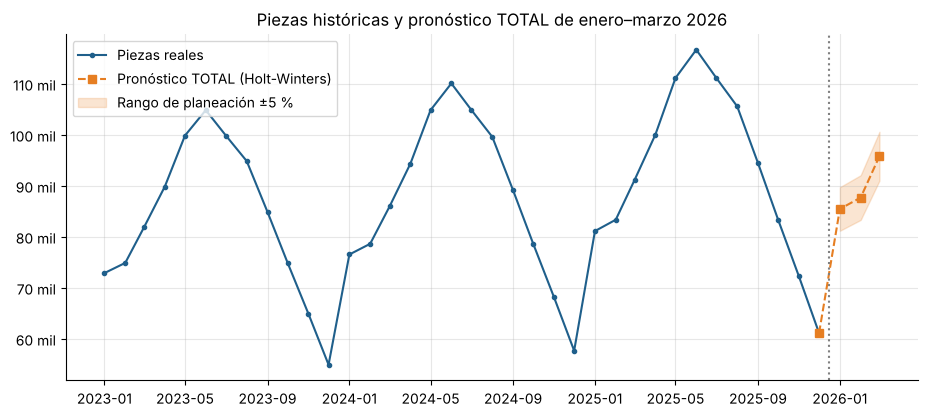

In [14]:
fig, ax = plt.subplots()
ax.plot(serie.index, serie, color=AZUL, marker="o", ms=3, label="Piezas reales")
ax.plot([serie.index[-1], *futuro.index], [serie.iloc[-1], *futuro], color=NARANJA,
        marker="s", ls="--", label="Pronóstico TOTAL (Holt-Winters)")
ax.fill_between(futuro.index, pronostico["minimo_piezas_-5%"], pronostico["maximo_piezas_+5%"],
                color=NARANJA, alpha=.2, label="Rango de planeación ±5 %")
ax.axvline(serie.index[-1] + pd.Timedelta(days=15), color="gray", ls=":")
ax.yaxis.set_major_formatter(miles); ax.legend(loc="upper left")
ax.set_title("Piezas históricas y pronóstico TOTAL de enero–marzo 2026")
plt.show()

**Supuestos:**
1. La tendencia y la estacionalidad de 2023–2025 continúan en 2026.
2. No hay cambios fuertes en clientes, capacidad de producción ni competencia.
3. El importe usa el **precio de 2025 ($15.00)**. Si el precio sube en enero, como en años anteriores, el importe sube aunque las piezas no cambien. Por eso el pronóstico principal está en **piezas**.

**Limitaciones:**
1. Los datos son **simulados y muy regulares**, por lo que el MAE es optimista.
2. Solo hay 3 ciclos anuales (cada factor estacional se estima con 3 datos) y la prueba usa solo 3 meses.
3. La base es mensual y registra **un solo producto y un canal por mes**, así que no permite pronosticar por producto ni medir la mezcla real.
4. No hay devoluciones ni costos, por lo que **no se calcula utilidad**.
5. **Un pronóstico no garantiza las ventas futuras.**

In [15]:
# Exportar resultados para el dashboard (Streamlit)
mensual = df.set_index("fecha")[["cantidad", "subtotal", "venta_total"]]
mensual.to_csv(SALIDA / "ventas_mensuales.csv", index_label="mes")
evaluacion.to_csv(SALIDA / "evaluacion_prueba.csv", index_label="mes")
mae.to_csv(SALIDA / "metricas_mae.csv", index=False)
pronostico.to_csv(SALIDA / "pronostico_futuro.csv")
estacional.set_axis(MESES).to_frame("indice").to_csv(SALIDA / "indice_estacional.csv", index_label="mes")
print("Archivos exportados:", *sorted(p.name for p in SALIDA.glob("*.csv")), sep="\n  ")

Archivos exportados:
  evaluacion_prueba.csv
  indice_estacional.csv
  metricas_mae.csv
  pronostico_futuro.csv
  ventas_mensuales.csv


## 7. Conclusiones y recomendaciones

In [16]:
print(f"1. Las piezas crecieron {anual['crecimiento_piezas_%'].iloc[1]:.1f}% en 2024 y {anual['crecimiento_piezas_%'].iloc[2]:.1f}% en 2025; "
      f"las ventas en pesos crecieron {anual['crecimiento_ventas_%'].iloc[2]:.1f}% en 2025 por el aumento de precio.")
print(f"2. Junio es el mes más alto (índice {estacional[6]:.2f}) y diciembre el más bajo ({estacional[12]:.2f}).")
print(f"3. Holt-Winters: MAE {mae.MAE_piezas[0]:,.0f} piezas vs {mae.MAE_piezas[1]:,.0f} del ingenuo.")
print(f"4. Pronóstico ene–mar 2026: {tot['pronostico_piezas']:,.0f} piezas "
      f"(≈ ${tot['importe_estimado_MXN_precio_15']:,.0f} MXN sin IVA a $15.00).")

1. Las piezas crecieron 5.0% en 2024 y 6.0% en 2025; las ventas en pesos crecieron 9.7% en 2025 por el aumento de precio.
2. Junio es el mes más alto (índice 1.26) y diciembre el más bajo (0.66).
3. Holt-Winters: MAE 79 piezas vs 22,225 del ingenuo.
4. Pronóstico ene–mar 2026: 268,937 piezas (≈ $4,034,055 MXN sin IVA a $15.00).


**Conclusiones**
1. JR Parking crece de forma sostenida: **+5 %** en piezas en 2024 y **+6 %** en 2025. En pesos crece más (**+9.7 %** en 2025) porque también subió el precio.
2. La demanda es **fuertemente estacional y predecible**: junio vende casi el doble que diciembre, y el patrón se repite igual cada año.
3. **Caja Limonera** es el producto principal y la **venta directa** el canal principal.
4. **Holt-Winters supera ampliamente al pronóstico ingenuo**, porque anticipa la caída de fin de año que el ingenuo ignora.
5. Para **enero–marzo 2026** se esperan unas **269 mil piezas** (≈ +5.2 % vs 2025), con marzo como el mes más alto del trimestre.

**Decisiones de negocio recomendadas**
1. **Producción e inventario:** aprovechar diciembre–enero (meses de baja demanda y capacidad ociosa) para **producir por adelantado** y llegar a marzo con inventario, ya que la demanda sube cada mes hasta junio. Programar la producción mensual con el pronóstico y tener inventario de seguridad hasta el límite superior (+5 %).
2. **Compra de materia prima:** negociar con proveedores de plástico reciclado la compra para el primer semestre **antes de enero**, con volúmenes basados en el pronóstico, y reducir compras en octubre–diciembre para no inmovilizar efectivo.
3. **Ventas en temporada baja:** lanzar en noviembre–diciembre promociones por volumen o preventa anticipada para clientes agrícolas, y fortalecer la venta en línea, para suavizar la caída de fin de año.